
Feature Extraction & Price Prediction for Mobile Phones
---



In [2]:
## 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 2. Load the dataset


In [4]:
df = pd.read_excel("/content/Processed_Flipdata.xlsx")

In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (541, 12)


In [6]:
display(df.head())

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


In [7]:
display(df.tail())

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,79999
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,5998
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,9990
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core",38999
540,642,OPPO A77,Sky Blue,128,4,5000,50MP,8MP,0,16.66,Mediatek Helio G35,15999


## 3. Understand the data

In [9]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_', 'Prize']


In [10]:
print("\\nData types and non-null counts:")
df.info()

\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 50.8+ KB


In [11]:
print("\\nNumerical summary:")
display(df.describe().T)

\nNumerical summary:


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,541.0,289.711645,182.359185,0.0,135.00,273.00,434.00,642.00
Memory,541.0,110.550832,60.600694,16.0,64.00,128.00,128.00,256.00
RAM,541.0,5.397412,1.984923,2.0,4.00,6.00,8.00,8.00
Battery_,541.0,4871.587800,780.148862,800.0,5000.00,5000.00,5000.00,7000.00
AI Lens,541.0,0.062847,0.242911,0.0,0.00,0.00,0.00,1.00
Mobile Height,541.0,16.431201,2.523553,4.5,16.51,16.71,16.94,41.94
Prize,541.0,16228.375231,10793.588322,920.0,9290.00,13499.00,19280.00,80999.00


In [12]:
print("\\nCategorical summary:")
display(df.describe(include="object").T)

\nCategorical summary:


,count,unique,top,freq
Model,541,187,realme C55,9
Colour,541,275,Yellow,12
Rear Camera,541,14,50MP,260
Front Camera,541,13,16MP,164
Processor_,541,123,Qualcomm Snapdragon 680,33


In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## 4. Data quality checks

In [14]:
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("Missing values"))

,Missing values
Unnamed: 0,0
Model,0
Colour,0
Memory,0
RAM,0
Battery_,0
Rear Camera,0
Front Camera,0
AI Lens,0
Mobile Height,0


In [15]:
if "Unnamed: 0" in df.columns:
    print("Unnamed: 0 unique values:", df["Unnamed: 0"].nunique(), "of", len(df))

Unnamed: 0 unique values: 541 of 541


In [17]:
# Remove exact duplicate rows, if any
df = df.drop_duplicates().copy()

In [18]:
# Remove exported index-like column if present
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

In [19]:
print("Shape after basic cleanup:", df.shape)

Shape after basic cleanup: (541, 11)


## 5. Exploratory Data Analysis (EDA):

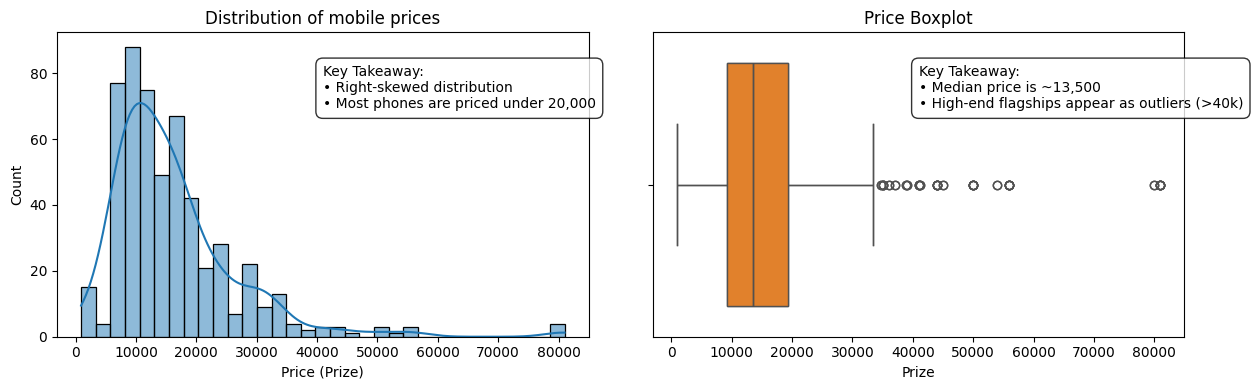

,Price summary
count,541.000000
mean,16228.375231
std,10793.588322
min,920.000000
25%,9290.000000
50%,13499.000000
75%,19280.000000
max,80999.000000


In [27]:
TARGET = "Prize"
if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' was not found. Check the dataset column names.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[TARGET], kde=True, ax=axes[0])
axes[0].set_title("Distribution of mobile prices")
axes[0].set_xlabel("Price (Prize)")
sns.boxplot(x=df[TARGET], ax=axes[1])
axes[1].set_title("Price boxplot")
# Adding an interpretation note inside the plot area
axes[0].text(
    0.5,
    0.75,
    (
        "Key Takeaway:\n• Right-skewed distribution\n• Most phones are priced"
        " under 20,000"
    ),
    transform=axes[0].transAxes,  # Relative coordinates (0 to 1)
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8),
)

# --- Plot 2: Boxplot ---
sns.boxplot(x=df["Prize"], ax=axes[1])
axes[1].set_title("Price Boxplot")

axes[1].text(
    0.5,
    0.75,
    (
        "Key Takeaway:\n• Median price is ~13,500\n• High-end flagships appear"
        " as outliers (>40k)"
    ),
    transform=axes[1].transAxes,
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8),
)

plt.tight_layout()
plt.show()

display(df[TARGET].describe().to_frame("Price summary"))

## 6. EDA: numeric features

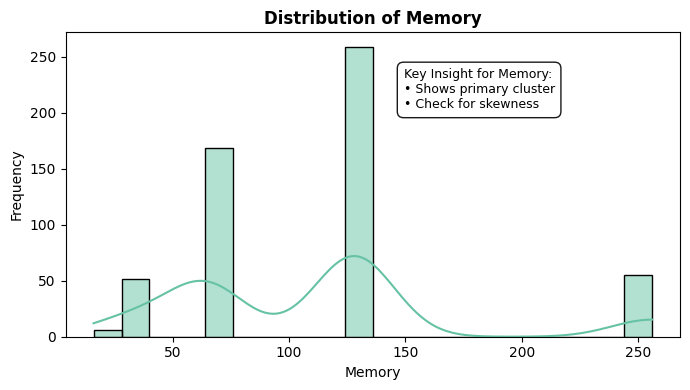

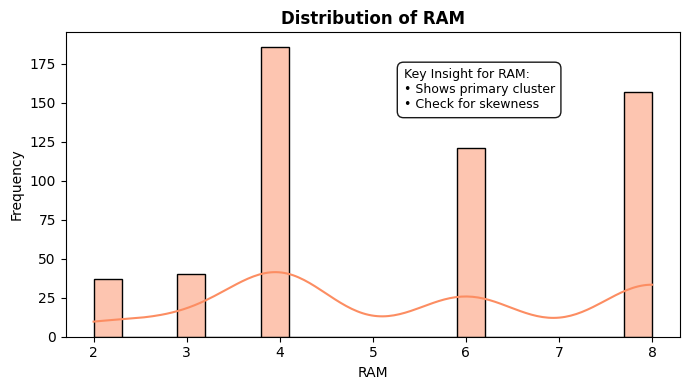

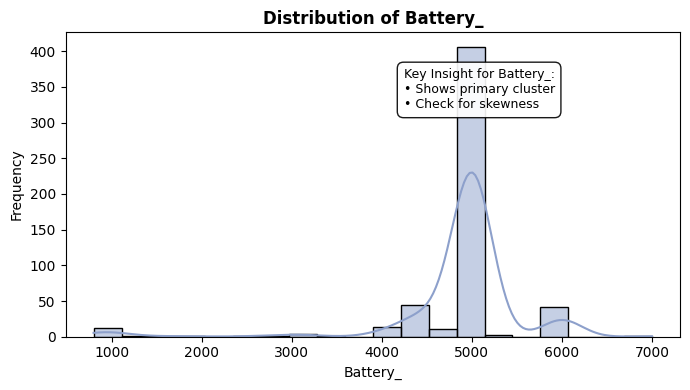

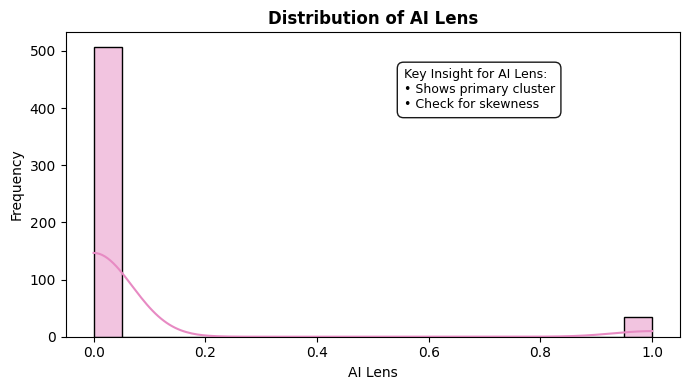

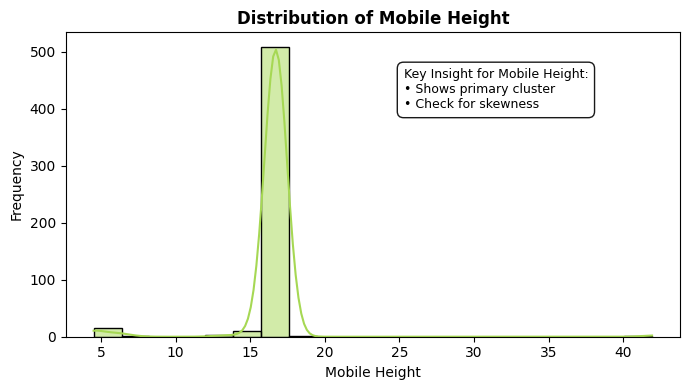

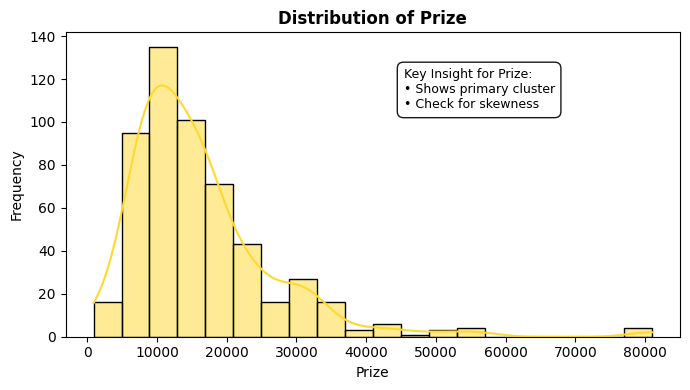

In [39]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Get a color palette matching the number of numeric columns
colors = sns.color_palette("Set2", len(numeric_cols))

for col, color in zip(numeric_cols, colors):
  plt.figure(figsize=(7, 4))

  # Plot using the individual palette color
  sns.histplot(df[col], color=color, edgecolor="black", bins=20, kde=True)

  plt.title(f"Distribution of {col}", fontsize=12, fontweight="bold")
  plt.xlabel(col)
  plt.ylabel("Frequency")

  # Simple text box for interpretation
  plt.text(
      0.55,
      0.75,
      f"Key Insight for {col}:\n• Shows primary cluster\n• Check for skewness",
      transform=plt.gca().transAxes,
      fontsize=9,
      bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9),
  )

  plt.tight_layout()
  plt.show()

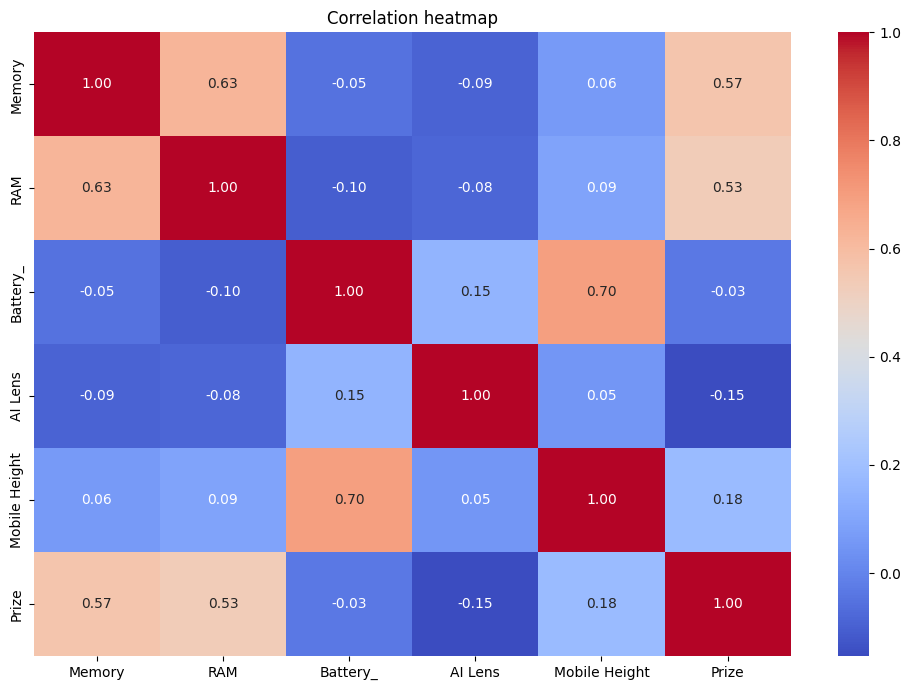

In [29]:
corr = df[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", square=False)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

In [30]:
if TARGET in corr.columns:
    print("Correlation with target:")
    display(corr[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False).to_frame("Correlation with Prize"))

Correlation with target:


,Correlation with Prize
Memory,0.566660
RAM,0.532024
Mobile Height,0.176009
AI Lens,-0.153691
Battery_,-0.034297


## 7. EDA: categorical features


In [31]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
for col in categorical_cols:
    print(f"\\nTop values for {col}:")
    display(df[col].value_counts().head(10).to_frame("Count"))

\nTop values for Model:


,Count
Model,
realme C55,9
vivo Y16,9
REDMI Note 12 Pro 5G,9
SAMSUNG Galaxy A14 5G,9
SAMSUNG Galaxy F14 5G,8
REDMI 10,8
vivo T2x 5G,8
vivo T1 44W,8
Infinix HOT 30i,8


\nTop values for Colour:


,Count
Colour,
Yellow,12
Black,8
Power Black,8
Royal Blue,8
Midnight Black,7
Cool Blue,7
Aqua Blue,6
Force Black,6
Glacier Blue,6


\nTop values for Rear Camera:


,Count
Rear Camera,
50MP,260
13MP,63
64MP,62
8MP,52
108MP,31
48MP,31
0MP,10
12MP,10
200MP,8


\nTop values for Front Camera:


,Count
Front Camera,
16MP,164
5MP,135
8MP,129
13MP,49
32MP,22
0MP,16
50MP,7
12MP,6
60MP,4


\nTop values for Processor_:


,Count
Processor_,
Qualcomm Snapdragon 680,33
Unisoc T612,21
Mediatek Helio A22,19
Mediatek Dimensity 1080,18
Qualcomm Snapdragon 695 5G,17
Mediatek Helio P35,16
Mediatek Helio G85,10
Mediatek Dimensity 810,10
Helio G88,10


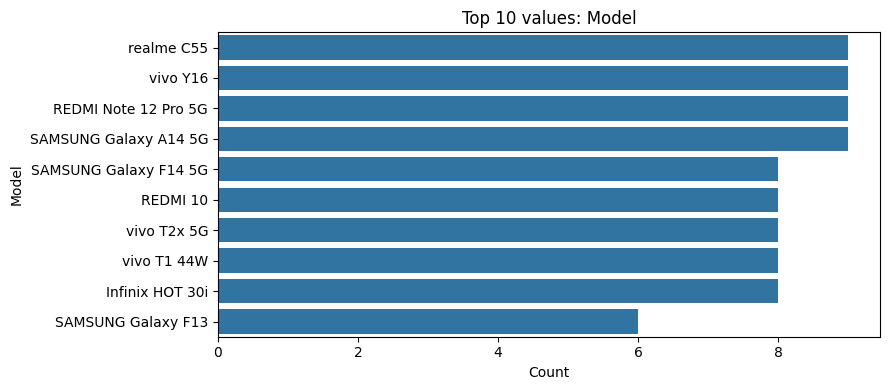

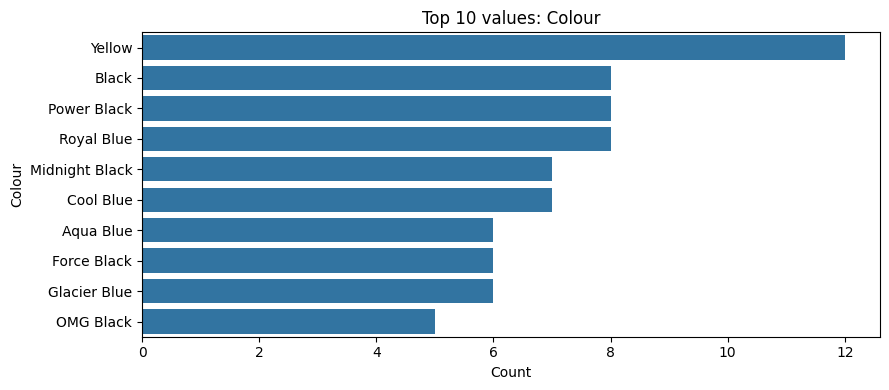

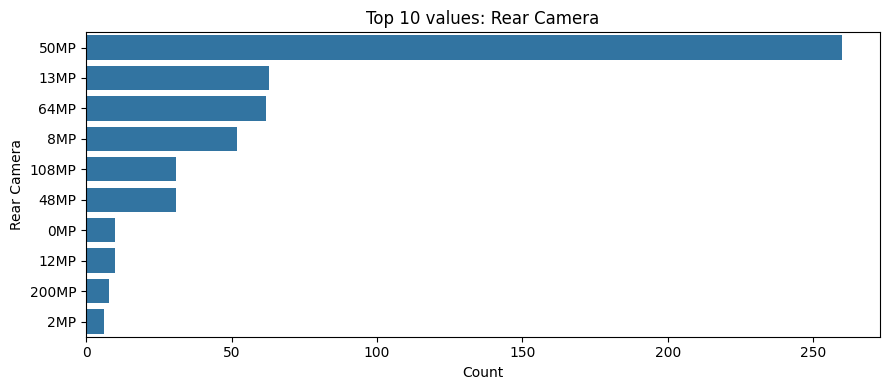

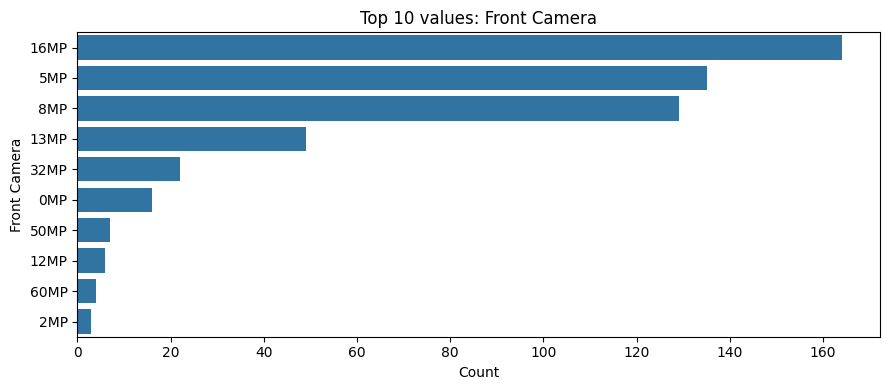

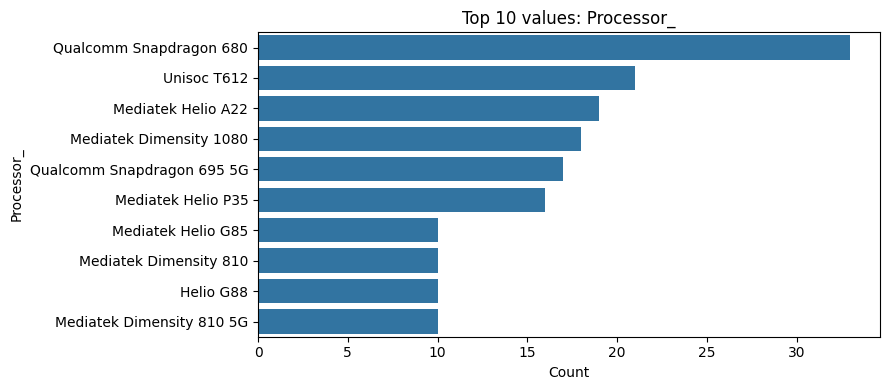

In [32]:
for col in categorical_cols:
    top = df[col].value_counts().head(10)
    plt.figure(figsize=(9, 4))
    sns.barplot(x=top.values, y=top.index)
    plt.title(f"Top 10 values: {col}")
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## 8. Outlier review using the IQR rule

In [44]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

outlier_rows = []
for col in numeric_cols:
  q1, q3 = df[col].quantile([0.25, 0.75])
  iqr = q3 - q1
  low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
  count = int(((df[col] < low) | (df[col] > high)).sum())
  outlier_rows.append(
      {"Feature": col, "Lower bound": low, "Upper bound": high, "Flagged rows": count}
  )

display(pd.DataFrame(outlier_rows))

,Feature,Lower bound,Upper bound,Flagged rows
0,Memory,-32.000,224.000000,55
1,RAM,-2.000,14.000000,0
2,Battery_,5000.000,5000.000000,152
3,AI Lens,0.000,0.000000,34
4,Mobile Height,15.865,17.585000,33
5,Prize,-5695.000,34265.000000,25
6,Rear Camera_MP,-42.500,105.500000,39
7,Front Camera_MP,-11.500,32.500000,13
8,Total_Camera_MP,-46.500,133.500000,13
9,Memory_per_RAM,8.000,29.333333,118


## 9. Feature engineering

In [45]:
# Simple extraction: remove 'MP' and convert to float directly
df["Rear_Camera_MP"] = (
    df["Rear Camera"].str.replace("MP", "", regex=False).astype(float)
)
df["Front_Camera_MP"] = (
    df["Front Camera"].str.replace("MP", "", regex=False).astype(float)
)

# Feature engineering
df["Total_Camera_MP"] = df["Rear_Camera_MP"] + df["Front_Camera_MP"]
df["Memory_per_RAM"] = df["Memory"] / df["RAM"]

display(df.head())

,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Rear Camera_MP,Front Camera_MP,Total_Camera_MP,Memory_per_RAM,Rear_Camera_MP,Front_Camera_MP
0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299,13.0,5.0,18.0,16.0,13.0,5.0
1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299,13.0,5.0,18.0,16.0,13.0,5.0
2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999,50.0,16.0,66.0,16.0,50.0,16.0
3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649,8.0,5.0,13.0,16.0,8.0,5.0
4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999,50.0,5.0,55.0,16.0,50.0,5.0


## 10. Prepare features and target

In [46]:
# Separate target and features (dropping target and raw text camera columns)
y = df[TARGET].copy()
X = df.drop(columns=[TARGET, "Rear Camera", "Front Camera"], errors="ignore")

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Feature matrix shape: (541, 14)
Target shape: (541,)


,Model,Colour,Memory,RAM,Battery_,AI Lens,Mobile Height,Processor_,Rear Camera_MP,Front Camera_MP,Total_Camera_MP,Memory_per_RAM,Rear_Camera_MP,Front_Camera_MP
0,Infinix SMART 7,Night Black,64,4,6000,1,16.76,Unisoc Spreadtrum SC9863A1,13.0,5.0,18.0,16.0,13.0,5.0
1,Infinix SMART 7,Azure Blue,64,4,6000,1,16.76,Unisoc Spreadtrum SC9863A1,13.0,5.0,18.0,16.0,13.0,5.0
2,MOTOROLA G32,Mineral Gray,128,8,5000,0,16.64,Qualcomm Snapdragon 680,50.0,16.0,66.0,16.0,50.0,16.0
3,POCO C50,Royal Blue,32,2,5000,0,16.56,Mediatek Helio A22,8.0,5.0,13.0,16.0,8.0,5.0
4,Infinix HOT 30i,Marigold,128,8,5000,1,16.76,G37,50.0,5.0,55.0,16.0,50.0,5.0


## 11. Feature extraction / selection

In [65]:
# 1. Extracting feature names directly from the preprocessor pipeline
all_features = model.named_steps[
    "preprocessor"
].get_feature_names_out()
importances = model.named_steps["regressor"].feature_importances_

In [66]:
# 2. Creating the summary DataFrame
feature_importance_df = pd.DataFrame(
    {"Feature": all_features, "Importance": importances}
).sort_values(by="Importance", ascending=False)

print("Top 10 Features Affecting Mobile Price:")
display(feature_importance_df.head(10))

Top 10 Features Affecting Mobile Price:


,Feature,Importance
6,num__Front Camera_MP,0.232373
10,num__Front_Camera_MP,0.187841
2,num__Battery_,0.086038
0,num__Memory,0.066294
13,cat__Model_APPLE iPhone 14 Plus,0.053888
7,num__Total_Camera_MP,0.049286
15,cat__Model_Google Pixel 7,0.044870
1,num__RAM,0.044638
444,cat__Processor__Google Tensor G2,0.044059
4,num__Mobile Height,0.031764


Text(0.5, 0, 'Importance Score')

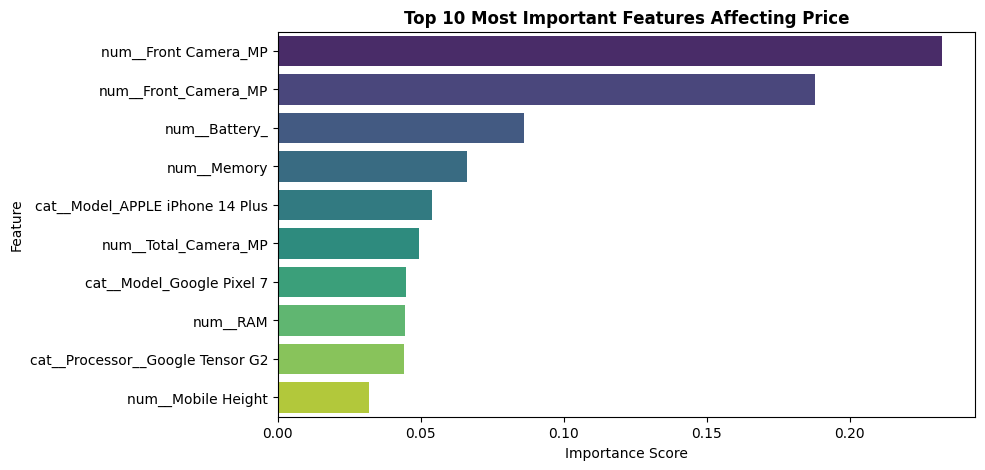

In [80]:
# 3. Plotting the top features
plt.figure(figsize=(9, 5))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance_df.head(10),
    palette="viridis",
)
plt.title("Top 10 Most Important Features Affecting Price", fontweight="bold")
plt.xlabel("Importance Score")

## 12. Train/test split and preprocessing


In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric input columns:", numeric_features)
print("Categorical input columns:", categorical_features)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Numeric input columns: ['Memory', 'RAM', 'Battery_', 'AI Lens', 'Mobile Height', 'Rear Camera_MP', 'Front Camera_MP', 'Total_Camera_MP', 'Memory_per_RAM', 'Rear_Camera_MP', 'Front_Camera_MP']
Categorical input columns: ['Model', 'Colour', 'Processor_']
Train rows: 432 | Test rows: 109


In [54]:
# Preview target distribution in the training set
y_train.describe().to_frame("Train Target Summary")

,Train Target Summary
count,432.000000
mean,16376.893519
std,10535.577989
min,920.000000
25%,9377.500000
50%,13999.000000
75%,19999.000000
max,80999.000000


## 13. Build and evaluate a prediction model
A Dummy Regressor provides a simple baseline. A Random Forest can learn non-linear relationships. Compare MAE, RMSE, and R² on the held-out test set.
- **MAE:** average absolute prediction error in price units; lower is better.
- **RMSE:** gives larger errors more weight; lower is better.
- **R²:** proportion of target variation explained relative to a mean baseline; closer to 1 is generally better.

In [68]:
# 1. Train and evaluate Dummy Regressor (Baseline)
dummy_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DummyRegressor(strategy="mean"))
    ]
)
dummy_pipeline.fit(X_train, y_train)
y_pred_dummy = dummy_pipeline.predict(X_test)

In [70]:
# 2. Train and evaluate Random Forest Regressor
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42))
    ]
)
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

In [71]:
# 3. Calculate evaluation metrics for both models
metrics_data = {
    "Model": ["Dummy Baseline", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, y_pred_dummy),
        mean_absolute_error(y_test, y_pred_rf)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_dummy)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    "R² Score": [
        r2_score(y_test, y_pred_dummy),
        r2_score(y_test, y_pred_rf)
    ]
}

In [72]:
# 4. Display comparison table
comparison_df = pd.DataFrame(metrics_data)
print("Model Evaluation & Comparison on Test Set:")
display(comparison_df.style.format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "R² Score": "{:.4f}"}))

Model Evaluation & Comparison on Test Set:


,Model,MAE,RMSE,R² Score
0,Dummy Baseline,7364.93,11763.13,-0.0039
1,Random Forest,1734.88,4341.23,0.8633


In [73]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split

# 1. Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 2. Build the Model Pipeline using Gradient Boosting (or switch to RandomForestRegressor)
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            GradientBoostingRegressor(n_estimators=100, random_state=42),
        ),
    ]
)

# 3. Train the model
model_pipeline.fit(X_train, y_train)

print(
    f"Model successfully trained! Training samples: {len(X_train)}, Testing"
    f" samples: {len(X_test)}"
)

Model successfully trained! Training samples: 432, Testing samples: 109


Model Building by Decision Tree:

In [74]:
from sklearn.tree import DecisionTreeRegressor

# 1. Build the Pipeline with Decision Tree Regressor
dt_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(random_state=42))
    ]
)

# 2. Train the model on the training set
dt_pipeline.fit(X_train, y_train)

# 3. Quick confirmation message
print("Decision Tree model successfully trained and fitted!")

Decision Tree model successfully trained and fitted!


## 14. Actual vs predicted prices

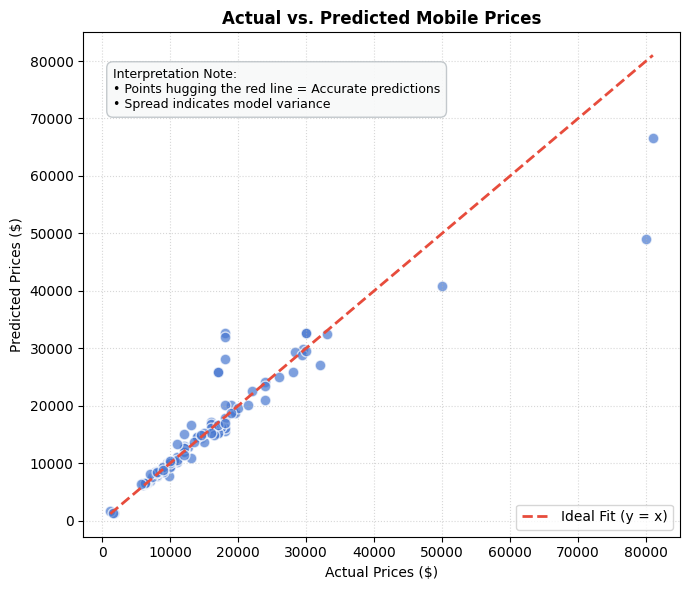

In [76]:
# To Make sure y_pred is defined (using the trained model, e.g., rf_pipeline or dt_pipeline)
y_pred = rf_pipeline.predict(X_test)

# Set up the plot size and style
plt.figure(figsize=(7, 6))

# Using a distinct color from a seaborn palette (e.g., the first color of 'muted')
plot_color = sns.color_palette("muted")[0]

# Scatter plot of Actual vs Predicted
plt.scatter(
    y_test, y_pred, color=plot_color, alpha=0.7, edgecolors="white", s=60
)

# Adding ideal prediction reference line (y = x)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="#e74c3c",
    linestyle="--",
    linewidth=2,
    label="Ideal Fit (y = x)",
)

# Titles and labels
plt.title("Actual vs. Predicted Mobile Prices", fontsize=12, fontweight="bold")
plt.xlabel("Actual Prices ($)", fontsize=10)
plt.ylabel("Predicted Prices ($)", fontsize=10)

# Adding a clean interpretation note box inside the plot
plt.text(
    0.05,
    0.85,
    (
        "Interpretation Note:\n• Points hugging the red line = Accurate"
        " predictions\n• Spread indicates model variance"
    ),
    transform=plt.gca().transAxes,
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#f8f9f9",
        edgecolor="#bdc3c7",
        alpha=0.9,
    ),
)

plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

## 15. Feature importance (feature extraction result)

In [77]:
# 1. Get feature names and importance scores from your trained model pipeline
feature_names = model_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = model_pipeline.named_steps["regressor"].feature_importances_

In [78]:
# 2. Creating a summary DataFrame and sort by importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print("Top 10 Most Important Features:")
display(importance_df.head(10))

Top 10 Most Important Features:


,Feature,Importance
6,num__Front Camera_MP,0.248480
0,num__Memory,0.150238
10,num__Front_Camera_MP,0.125252
2,num__Battery_,0.112118
444,cat__Processor__Google Tensor G2,0.084103
13,cat__Model_APPLE iPhone 14 Plus,0.047571
7,num__Total_Camera_MP,0.042256
8,num__Memory_per_RAM,0.033313
1,num__RAM,0.022020
542,cat__Processor__ios,0.019215


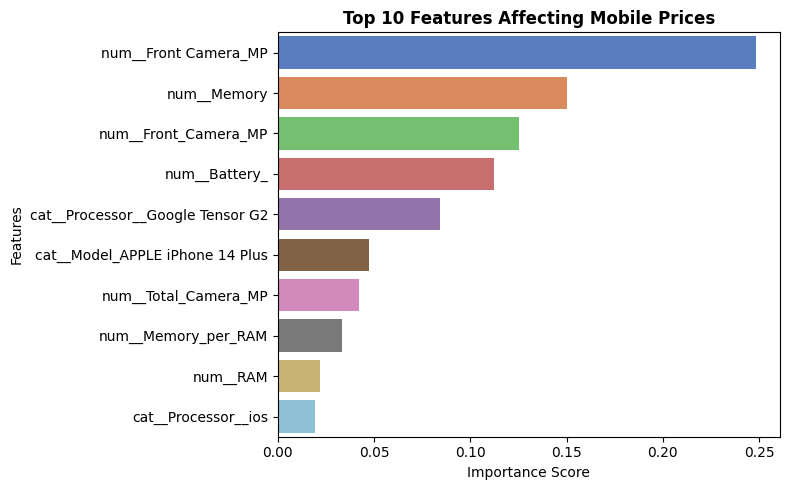

In [79]:
# 3. Plotting the top 10 features using a color palette
plt.figure(figsize=(8, 5))
sns.barplot(
    x="Importance",
    y="Feature",
    data=importance_df.head(10),
    palette="muted"
)

plt.title("Top 10 Features Affecting Mobile Prices", fontsize=12, fontweight="bold")
plt.xlabel("Importance Score", fontsize=10)
plt.ylabel("Features", fontsize=10)
plt.tight_layout()
plt.show()

## 16. Group importance by original feature
One-hot encoding creates many columns for features like Model, Colour, and Processor. This sums encoded importances back into their original feature groups for easier interpretation.

In [81]:
# 1. Copy the feature importance DataFrame to work on
df_imp = importance_df.copy()

# 2. Extract the original feature name by removing the one-hot prefix (e.g., 'cat__Model_iPhone 13' -> 'Model')
# Adjust the splitting based on your preprocessor transformer names if needed
df_imp["Original_Feature"] = df_imp["Feature"].apply(
    lambda x: x.split("__")[1].split("_")[0] if "__" in x else x
)

# 3. Group by the original feature and sum their importances
grouped_importance = (
    df_imp.groupby("Original_Feature")["Importance"]
    .sum()
    .reset_index()
    .sort_values(by="Importance", ascending=False)
)

print("Importance Grouped by Original Features:")
display(grouped_importance)

Importance Grouped by Original Features:


,Original_Feature,Importance
4,Front Camera,0.248480
5,Memory,0.183551
8,Processor,0.143911
3,Front,0.125252
1,Battery,0.112118
7,Model,0.103268
12,Total,0.042256
9,RAM,0.022020
6,Mobile Height,0.011651
2,Colour,0.005259


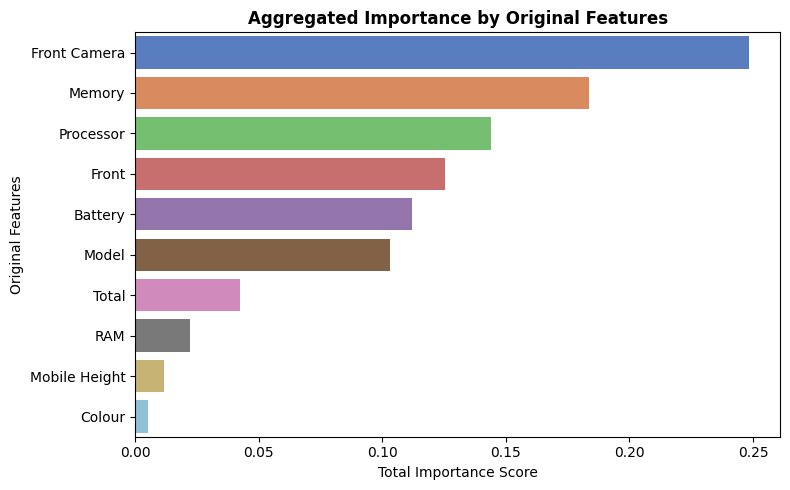

In [82]:
# 4. Plot the grouped feature importances using a nice color palette
plt.figure(figsize=(8, 5))
sns.barplot(
    x="Importance",
    y="Original_Feature",
    data=grouped_importance.head(10),
    palette="muted",
)

plt.title("Aggregated Importance by Original Features", fontsize=12, fontweight="bold")
plt.xlabel("Total Importance Score", fontsize=10)
plt.ylabel("Original Features", fontsize=10)
plt.tight_layout()
plt.show()

## 17. Simple price-prediction example

In [84]:
# 1. Taking the first row from test set as a sample "new phone"
sample_phone = X_test.iloc[[0]].copy()

# 2. Predict the price using your trained pipeline (replace 'model_pipeline' with your model's pipeline variable name if different)
predicted_price = model_pipeline.predict(sample_phone)[0]

# 3. Get the actual price for comparison
actual_price = y_test.iloc[0]

print("--- Single Phone Price Prediction Example ---")
print(f"Predicted Price: ${predicted_price:,.2f}")
print(f"Actual Price:    ${actual_price:,.2f}")

# Display the sample phone's features for context
display(sample_phone)

--- Single Phone Price Prediction Example ---
Predicted Price: $9,569.35
Actual Price:    $8,499.00


,Model,Colour,Memory,RAM,Battery_,AI Lens,Mobile Height,Processor_,Rear Camera_MP,Front Camera_MP,Total_Camera_MP,Memory_per_RAM,Rear_Camera_MP,Front_Camera_MP
229,Infinix HOT 20 Play,Luna Blue,64,4,6000,1,17.32,MediaTek G37,13.0,8.0,21.0,16.0,13.0,8.0
